In [ ]:
""" Design and automate data ingestion pipelines and preprocessing workflows, using tools like Airflow or Prefect, to enable efficient, fault-tolerant, and scalable data preparation for downstream ML tasks."""

' Generate personalized, data-driven recommendations from advanced machine learning models by applying domain-specific rules,\n collaborative filtering, or reinforcement learning techniques to maximize business impact.'

In [2]:
# import libraries
import time
import functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [3]:
# define task execution decorator with retries and logging
task_logs = []

def task(name, retries=2, delay=0.1):
    def decorator(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            attempt = 0
            start_time = time.time()
            while attempt <= retries:
                try:
                    result = func(*args, **kwargs)
                    duration = round(time.time() - start_time, 3)
                    task_logs.append({'task': name, 'status': 'success', 'duration': duration, 'retries': attempt})
                    print(f"task '{name}' completed in {duration}s")
                    return result
                except Exception as e:
                    attempt += 1
                    if attempt > retries:
                        duration = round(time.time() - start_time, 3)
                        task_logs.append({'task': name, 'status': 'failed', 'duration': duration, 'error': str(e)})
                        print(f"task '{name}' failed: {e}")
                        raise
                    time.sleep(delay)
        return wrapper
    return decorator

In [4]:
# define ingestion and validation tasks
@task(name="ingest_raw_sales_data")
def ingest_data(file_path):
    return pd.read_csv(file_path)

@task(name="validate_raw_data")
def validate_data(df):
    required = ['date', 'units_sold', 'unit_price', 'stock_level', 'region', 'category']
    for col in required:
        if col not in df.columns:
            raise ValueError(f"missing column: {col}")
    if df['units_sold'].isnull().sum() > 0:
        raise ValueError("nulls in units_sold")
    return df

In [5]:
# define cleaning and feature engineering tasks
@task(name="clean_sales_records")
def clean_data(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])
    df = df.dropna().drop_duplicates()
    df = df[df['units_sold'] >= 0]
    return df

@task(name="engineer_ml_features")
def engineer_features(df):
    df = df.copy()
    df['day_of_week'] = df['date'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['revenue'] = df['units_sold'] * df['unit_price']
    df['stock_turnover'] = (df['units_sold'] / (df['stock_level'] + 1)).round(4)
    scaler = StandardScaler()
    cols = ['stock_level', 'unit_price', 'expiry_days_remaining']
    df[[f'{c}_scaled' for c in cols]] = scaler.fit_transform(df[cols])
    return df

In [6]:
# define export task for downstream ml data
@task(name="export_ml_dataset")
def export_dataset(df, output_path="processed_ml_sales.csv"):
    df.to_csv(output_path, index=False)
    return output_path

In [7]:
# orchestrate and run automated workflow
def run_workflow(source_file):
    print("starting automated data pipeline workflow...")
    raw = ingest_data(source_file)
    val = validate_data(raw)
    cln = clean_data(val)
    feat = engineer_features(cln)
    path = export_dataset(feat)
    print(f"workflow finished successfully, saved to {path}")
    return feat

processed_df = run_workflow('global_pharmacy_sales_data.csv')
processed_df.head()

starting automated data pipeline workflow...
task 'ingest_raw_sales_data' completed in 0.192s
task 'validate_raw_data' completed in 0.0s
task 'clean_sales_records' completed in 0.192s
task 'engineer_ml_features' completed in 0.042s
task 'export_ml_dataset' completed in 2.124s
workflow finished successfully, saved to processed_ml_sales.csv


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,day_of_week,is_weekend,revenue,stock_turnover,stock_level_scaled,unit_price_scaled,expiry_days_remaining_scaled
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0,6,1,14884.64,0.0687,0.637568,-0.261569,0.459834
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1,1,0,28006.79,0.0809,0.089103,0.836679,-0.966799
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1,2,0,21339.48,0.2409,-1.787221,-1.095741,0.910350
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0,6,1,17404.75,0.0605,-0.026363,0.391690,-0.220945
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0,0,0,24929.64,0.1314,-0.776893,-0.301691,1.080545


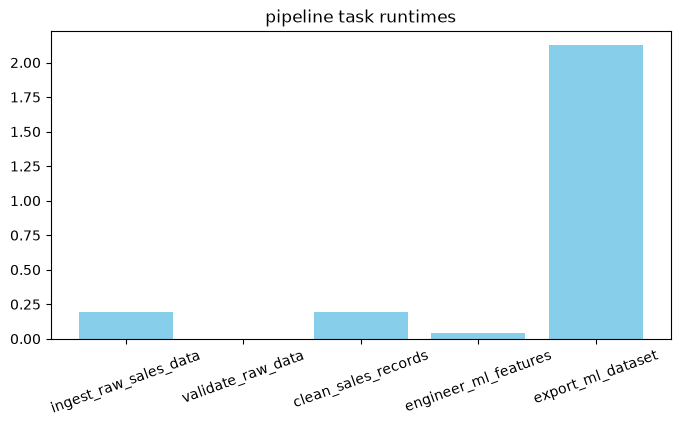

In [8]:
# easy plot of task runtimes
logs_df = pd.DataFrame(task_logs)
plt.figure(figsize=(8, 4))
plt.bar(logs_df['task'], logs_df['duration'], color='skyblue')
plt.title('pipeline task runtimes')
plt.xticks(rotation=20)
plt.show()

In [9]:
# verify ml ready dataset for downstream tasks
ready_df = pd.read_csv('processed_ml_sales.csv')
print("dataset shape:", ready_df.shape)
print("columns:", list(ready_df.columns))
ready_df[['units_sold', 'revenue', 'stock_turnover', 'stock_level_scaled']].head()

dataset shape: (175360, 21)
columns: ['date', 'year', 'month', 'day', 'region', 'country', 'category', 'medicine', 'age_group', 'units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'day_of_week', 'is_weekend', 'revenue', 'stock_turnover', 'stock_level_scaled', 'unit_price_scaled', 'expiry_days_remaining_scaled']


,units_sold,revenue,stock_turnover,stock_level_scaled
0,328,14884.64,0.0687,0.637568
1,371,28006.79,0.0809,0.089103
2,948,21339.48,0.2409,-1.787221
3,275,17404.75,0.0605,-0.026363
4,563,24929.64,0.1314,-0.776893
